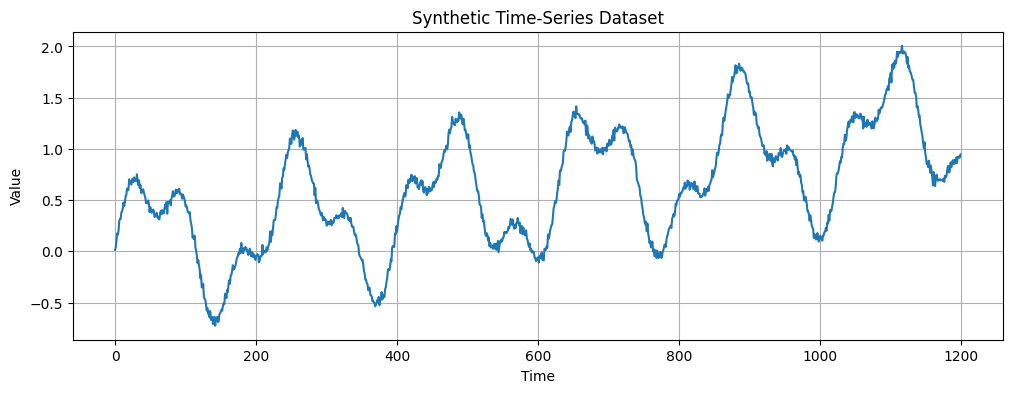

Dataset shape: (1200,)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate synthetic time-series data
time = np.arange(1200)

data = (
    0.6 * np.sin(0.03 * time)
    + 0.3 * np.sin(0.08 * time)
    + 0.001 * time
    + np.random.normal(0, 0.03, len(time))
)

# Visualize the data
plt.figure(figsize=(12, 4))
plt.plot(time, data)
plt.title("Synthetic Time-Series Dataset")
plt.xlabel("Time")
plt.ylabel("Value")
plt.grid(True)
plt.show()

print("Dataset shape:", data.shape)

In [ ]:
# Chronological train/test split
split_index = int(len(data) * 0.8)

train_data = data[:split_index]
test_data = data[split_index:]

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

# Fit the scaler ONLY on training data
minimum = train_data.min()
maximum = train_data.max()

# Scale the complete series using training statistics
scaled_data = (data - minimum) / (maximum - minimum)

print("Scaled data range:", scaled_data.min(), "to", scaled_data.max())

Training observations: 960
Testing observations: 240
Scaled data range: 0.0 to 1.0686019415248043


In [ ]:
SEQUENCE_LENGTH = 20

X_train = []
y_train = []

X_test = []
y_test = []

# The target index determines whether a sample belongs
# to training or testing.
for target_idx in range(SEQUENCE_LENGTH, len(scaled_data)):

    # Previous 20 observations
    window = scaled_data[
        target_idx - SEQUENCE_LENGTH : target_idx
    ]

    # The next observation
    target = scaled_data[target_idx]

    if target_idx < split_index:
        X_train.append(window)
        y_train.append(target)
    else:
        X_test.append(window)
        y_test.append(target)

# Convert lists into NumPy arrays
X_train = np.array(X_train).reshape(-1, SEQUENCE_LENGTH, 1)
y_train = np.array(y_train).reshape(-1, 1)

X_test = np.array(X_test).reshape(-1, SEQUENCE_LENGTH, 1)
y_test = np.array(y_test).reshape(-1, 1)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (940, 20, 1)
y_train: (940, 1)
X_test: (240, 20, 1)
y_test: (240, 1)


In [ ]:
class SimpleRNN:

    def __init__(self, input_size, hidden_size, output_size):

        self.hidden_size = hidden_size

        # Input-to-hidden weights
        self.Wx = np.random.randn(
            input_size, hidden_size
        ) * 0.1

        # Hidden-to-hidden recurrent weights
        self.Wh = np.random.randn(
            hidden_size, hidden_size
        ) * 0.1

        # Hidden-to-output weights
        self.Wy = np.random.randn(
            hidden_size, output_size
        ) * 0.1

        # Biases
        self.bh = np.zeros((1, hidden_size))
        self.by = np.zeros((1, output_size))

    def forward(self, X):

        batch_size, sequence_length, _ = X.shape

        # Initial hidden state
        h = np.zeros((batch_size, self.hidden_size))

        # Save hidden states for backpropagation
        hidden_states = [h]

        # Process the sequence one time step at a time
        for t in range(sequence_length):

            x_t = X[:, t, :]

            h = np.tanh(
                x_t @ self.Wx
                + h @ self.Wh
                + self.bh
            )

            hidden_states.append(h)

        # Predict using the final hidden state
        y_pred = h @ self.Wy + self.by

        return y_pred, hidden_states

    def train_step(self, X, y, learning_rate=0.01):

        batch_size = X.shape[0]

        # -------------------------
        # 1. Forward propagation
        # -------------------------
        y_pred, hidden_states = self.forward(X)

        error = y_pred - y

        loss = 0.5 * np.mean(error ** 2)

        # -------------------------
        # 2. Output-layer gradients
        # -------------------------
        dWy = hidden_states[-1].T @ (error / batch_size)
        dby = np.sum(error / batch_size, axis=0, keepdims=True)

        # Gradient flowing into final hidden state
        dh = (error / batch_size) @ self.Wy.T

        dWx = np.zeros_like(self.Wx)
        dWh = np.zeros_like(self.Wh)
        dbh = np.zeros_like(self.bh)

        # -------------------------
        # 3. Backpropagation Through Time
        # -------------------------
        for t in reversed(range(X.shape[1])):

            h_t = hidden_states[t + 1]
            h_prev = hidden_states[t]

            x_t = X[:, t, :]

            # Derivative of tanh
            da = dh * (1 - h_t ** 2)

            # Accumulate gradients
            dWx += x_t.T @ da
            dWh += h_prev.T @ da
            dbh += np.sum(da, axis=0, keepdims=True)

            # Send gradient to previous hidden state
            dh = da @ self.Wh.T

        # -------------------------
        # 4. Clip gradients
        # -------------------------
        gradients = [dWx, dWh, dWy, dbh, dby]

        for grad in gradients:
            np.clip(grad, -1, 1, out=grad)

        # -------------------------
        # 5. Update parameters
        # -------------------------
        self.Wx -= learning_rate * dWx
        self.Wh -= learning_rate * dWh
        self.Wy -= learning_rate * dWy

        self.bh -= learning_rate * dbh
        self.by -= learning_rate * dby

        return loss

Epoch 50/500, Loss: 0.063638
Epoch 100/500, Loss: 0.034085
Epoch 150/500, Loss: 0.025113
Epoch 200/500, Loss: 0.022346
Epoch 250/500, Loss: 0.021376
Epoch 300/500, Loss: 0.020904
Epoch 350/500, Loss: 0.020565
Epoch 400/500, Loss: 0.020258
Epoch 450/500, Loss: 0.019956
Epoch 500/500, Loss: 0.019651


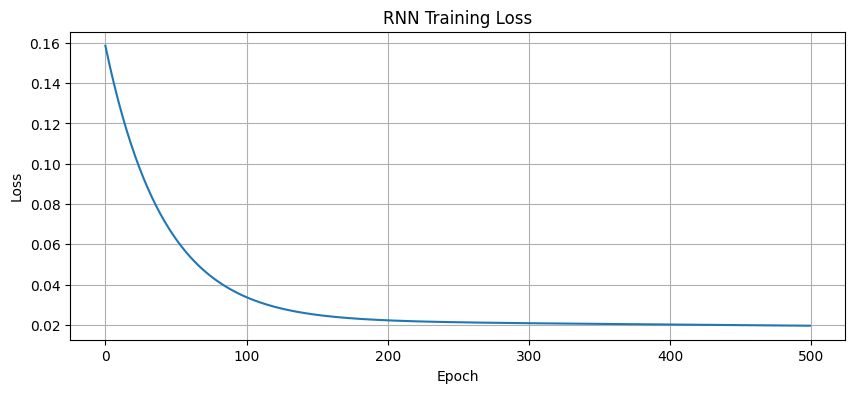

In [ ]:
# Initialize the RNN
model = SimpleRNN(
    input_size=1,
    hidden_size=16,
    output_size=1
)

EPOCHS = 500
LEARNING_RATE = 0.01

loss_history = []

for epoch in range(EPOCHS):

    loss = model.train_step(
        X_train,
        y_train,
        learning_rate=LEARNING_RATE
    )

    loss_history.append(loss)

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}/{EPOCHS}, Loss: {loss:.6f}")

# Plot training loss
plt.figure(figsize=(10, 4))
plt.plot(loss_history)
plt.title("RNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

Test MAE: 0.5427


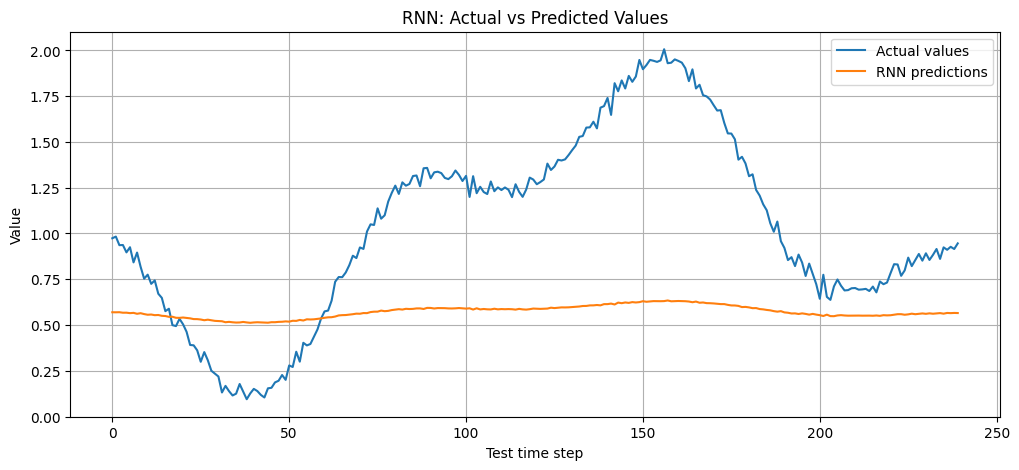

In [ ]:
# Testing: no parameter updates
test_predictions, _ = model.forward(X_test)

# Convert predictions and targets back to original scale
predictions_original = (
    test_predictions * (maximum - minimum) + minimum
)

actual_original = (
    y_test * (maximum - minimum) + minimum
)

# Mean Absolute Error
mae = np.mean(
    np.abs(predictions_original - actual_original)
)

print(f"Test MAE: {mae:.4f}")

# Plot predictions against actual values
plt.figure(figsize=(12, 5))

plt.plot(
    actual_original,
    label="Actual values"
)

plt.plot(
    predictions_original,
    label="RNN predictions"
)

plt.title("RNN: Actual vs Predicted Values")
plt.xlabel("Test time step")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.show()